Transformer para reconocimiento de acordes de guitarra

In [1]:
import os
import math
import time
import queue

import librosa
import numpy as np
import matplotlib.pyplot as plt

import sounddevice as sd
import soundfile as sf

import torch
import torch.nn as nn
import torch.nn.functional as F

import pytorch_lightning as pl

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

In [2]:
DATASET_PATH = "DatasetG\\GUITAR CHORDS V3"

SAMPLE_RATE = 22050
DURATION = 3
SAMPLES_PER_TRACK = SAMPLE_RATE * DURATION

N_MFCC = 40

BATCH_SIZE = 32
EPOCHS = 10

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
paths = []
labels = []

for root, dirs, files in os.walk(DATASET_PATH):

    for file in files:

        if file.endswith(".wav"):

            path = os.path.join(root, file)

            label = os.path.basename(root)

            paths.append(path)
            labels.append(label)

print("Cantidad de audios:", len(paths))
print("Clases:", sorted(set(labels)))

Cantidad de audios: 2000
Clases: ['A', 'Am', 'Bb', 'Bdim', 'C', 'Dm', 'Em', 'F', 'G']


### 📊 Dataset cargado

2000 audios — 9 acordes — distribución balanceada (~220 por clase).  
No se aplica data augmentation: el dataset ya está balanceado.

In [4]:
from collections import Counter

print('Total audios:', len(paths))
print('Distribucion:', dict(sorted(Counter(labels).items())))

Total audios: 2000
Distribucion: {'A': 240, 'Am': 220, 'Bb': 220, 'Bdim': 220, 'C': 220, 'Dm': 220, 'Em': 220, 'F': 220, 'G': 220}


Codificar etiquetas

In [5]:
encoder = LabelEncoder()
labels_encoded = encoder.fit_transform(labels)

NUM_CLASSES = len(encoder.classes_)

print(encoder.classes_)

['A' 'Am' 'Bb' 'Bdim' 'C' 'Dm' 'Em' 'F' 'G']


Extraer MFCC

In [6]:
def extract_mfcc(file_path):

    signal, sr = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        duration=DURATION
    )

    if len(signal) < SAMPLES_PER_TRACK:

        padding = SAMPLES_PER_TRACK - len(signal)

        signal = np.pad(signal, (0, padding))

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=N_MFCC
    )

    mfcc = mfcc.T

    return mfcc

Visualizar MFCC

(130, 40)


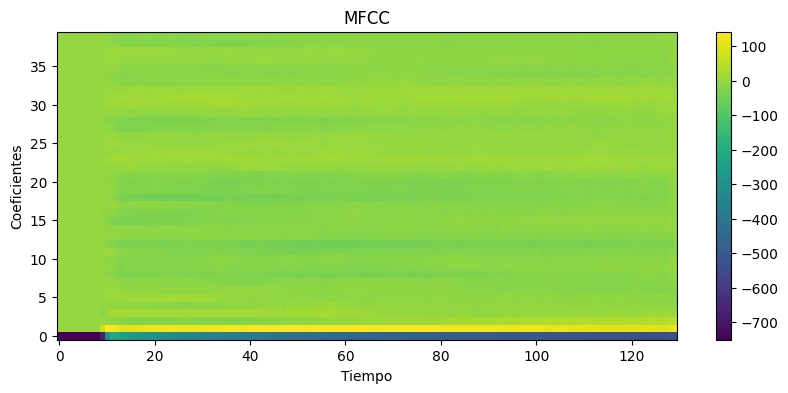

In [7]:
sample = extract_mfcc(paths[0])

print(sample.shape)

plt.figure(figsize=(10,4))
plt.imshow(sample.T, aspect='auto', origin='lower')
plt.title("MFCC")
plt.xlabel("Tiempo")
plt.ylabel("Coeficientes")
plt.colorbar()
plt.show()

In [8]:
# ── Dataset simple (sin augmentation) ─────────────────────────────────
class AudioDatasetMem(Dataset):

    def __init__(self, path_label_pairs):
        self.pairs = path_label_pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        path, label = self.pairs[idx]
        mfcc = torch.tensor(extract_mfcc(path)).float()
        return mfcc, torch.tensor(label).long()

# ── Split y DataLoaders ──────────────────────────────────────────────────
pairs = list(zip(paths, labels_encoded))

X_train_p, X_test_p, _, _ = train_test_split(
    pairs,
    labels_encoded,
    test_size=0.15,
    random_state=42,
    stratify=labels_encoded
)

train_dataset = AudioDatasetMem(X_train_p)
test_dataset  = AudioDatasetMem(X_test_p)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print('Train:', len(train_dataset), '| Test:', len(test_dataset))
x_s, y_s = next(iter(train_loader))
print('Batch shape:', x_s.shape, y_s.shape)

Train: 1700 | Test: 300
Batch shape: torch.Size([32, 130, 40]) torch.Size([32])


Multi Head Attention

In [9]:
class MultiHeadAttention(nn.Module):

    def __init__(self, n_embd, n_heads):

        super().__init__()

        self.n_heads = n_heads

        self.key = nn.Linear(n_embd, n_embd * n_heads)
        self.query = nn.Linear(n_embd, n_embd * n_heads)
        self.value = nn.Linear(n_embd, n_embd * n_heads)

        self.proj = nn.Linear(n_embd * n_heads, n_embd)

    def forward(self, x):

        B, L, F = x.size()

        k = self.key(x).view(B, L, F, self.n_heads).transpose(1,3)

        q = self.query(x).view(B, L, F, self.n_heads).transpose(1,3)

        v = self.value(x).view(B, L, F, self.n_heads).transpose(1,3)

        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))

        att = torch.softmax(att, dim=-1)

        y = att @ v

        y = y.transpose(1,2).contiguous().view(
            B,
            L,
            F * self.n_heads
        )

        return self.proj(y)

Transformer Block

In [10]:
class TransformerBlock(nn.Module):

    def __init__(self, n_embd, n_heads):

        super().__init__()

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

        self.attn = MultiHeadAttention(
            n_embd,
            n_heads
        )

        self.mlp = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd)
        )

    def forward(self, x):

        x = self.ln1(x + self.attn(x))

        x = self.ln2(x + self.mlp(x))

        return x

Modelo Transformer

In [11]:
class AudioTransformer(pl.LightningModule):

    def __init__(
        self,
        n_input=N_MFCC,
        n_embd=64,
        n_heads=4,
        n_layers=2,
        n_classes=NUM_CLASSES
    ):

        super().__init__()

        self.embedding = nn.Linear(n_input, n_embd)

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, 130, n_embd)
        )

        self.transformer = nn.Sequential(
            *[
                TransformerBlock(n_embd, n_heads)
                for _ in range(n_layers)
            ]
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(130 * n_embd, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes)
        )

    def forward(self, x):

        x = self.embedding(x)

        x = x + self.pos_embedding[:, :x.size(1), :]

        x = self.transformer(x)

        x = self.classifier(x)

        return x

    def compute_loss_acc(self, batch):

        x, y = batch

        y_hat = self(x)

        loss = F.cross_entropy(y_hat, y)

        preds = torch.argmax(y_hat, dim=1)

        acc = (preds == y).float().mean()

        return loss, acc

    def training_step(self, batch, batch_idx):

        loss, acc = self.compute_loss_acc(batch)

        self.log("train_loss", loss)

        self.log("train_acc", acc, prog_bar=True)

        return loss

    def validation_step(self, batch, batch_idx):

        loss, acc = self.compute_loss_acc(batch)

        self.log("val_loss", loss, prog_bar=True)

        self.log("val_acc", acc, prog_bar=True)

    def configure_optimizers(self):

        return torch.optim.Adam(
            self.parameters(),
            lr=0.0003
        )

    def predict_audio(self, x):

        with torch.no_grad():

            y_hat = self(x)

            probs = torch.softmax(y_hat, dim=1)

            preds = torch.argmax(probs, dim=1)

            return preds, probs

Crear modelo

In [12]:
model = AudioTransformer()

Entrenamiento

In [13]:
# ── Historial de métricas ──────────────────────────────────────────
from pytorch_lightning.callbacks import Callback

class MetricsHistory(Callback):
    def __init__(self):
        self.train_loss = []
        self.train_acc  = []
        self.val_loss   = []
        self.val_acc    = []

    def on_train_epoch_end(self, trainer, pl_module):
        m = trainer.callback_metrics
        self.train_loss.append(float(m.get("train_loss", 0)))
        self.train_acc.append(float(m.get("train_acc",  0)))

    def on_validation_epoch_end(self, trainer, pl_module):
        m = trainer.callback_metrics
        self.val_loss.append(float(m.get("val_loss", 0)))
        self.val_acc.append(float(m.get("val_acc",  0)))

metrics_history = MetricsHistory()

trainer = pl.Trainer(
    max_epochs=EPOCHS,
    accelerator="auto",
    log_every_n_steps=10,
    callbacks=[metrics_history]
)

trainer.fit(
    model,
    train_loader,
    test_loader
)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
c:\Users\Gerson\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheck

┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ embedding    │ Linear     │  2.6 K │ train │     0 │
│ 1 │ transformer  │ Sequential │  199 K │ train │     0 │
│ 2 │ classifier   │ Sequential │  1.1 M │ train │     0 │
│   │ other params │ n/a        │  8.3 K │ n/a   │   n/a │
└───┴──────────────┴────────────┴────────┴───────┴───────┘

Trainable params: 1.3 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.3 M                                                                                                
Total estimated model params size (MB): 5                                                                          
Modules in train mode: 32                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

c:\Users\Gerson\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21
: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

c:\Users\Gerson\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\trainer\connectors\data
_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

c:\Users\Gerson\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\trainer\connectors\data
_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing
the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

`Trainer.fit` stopped: `max_epochs=10` reached.


Evaluación

In [14]:
# ── Evaluación ─────────────────────────────────────────────────────
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()

all_preds  = []
all_labels = []

for x, y in test_loader:
    x = x.to(model.device)
    preds, probs = model.predict_audio(x)
    all_preds.extend(preds.cpu().numpy())
    all_labels.extend(y.numpy())

class_names = encoder.classes_

print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    zero_division=0
))


              precision    recall  f1-score   support

           A       1.00      1.00      1.00        36
          Am       0.97      0.91      0.94        33
          Bb       0.97      0.88      0.92        33
        Bdim       0.82      0.97      0.89        33
           C       0.96      0.82      0.89        33
          Dm       1.00      0.88      0.94        33
          Em       0.78      0.85      0.81        33
           F       1.00      0.94      0.97        33
           G       0.75      0.91      0.82        33

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.91       300
weighted avg       0.92      0.91      0.91       300



### Curvas de entrenamiento

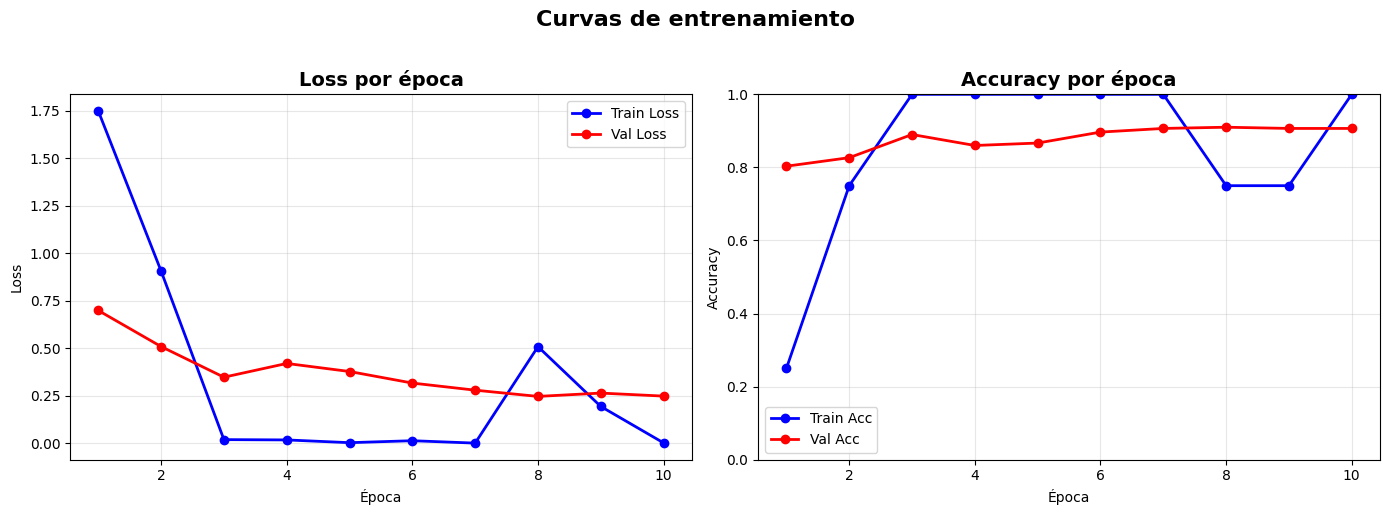

Guardada: curvas_entrenamiento.png


In [15]:
# ── Curvas de entrenamiento: Loss y Accuracy ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# val tiene 1 valor extra (validación antes de entrenar), lo descartamos
train_loss = metrics_history.train_loss
train_acc  = metrics_history.train_acc
val_loss   = metrics_history.val_loss[-len(train_loss):]
val_acc    = metrics_history.val_acc[-len(train_acc):]

epochs_range = range(1, len(train_loss) + 1)

# Loss
axes[0].plot(epochs_range, train_loss, 'b-o', label='Train Loss', linewidth=2)
axes[0].plot(epochs_range, val_loss,   'r-o', label='Val Loss',   linewidth=2)
axes[0].set_title('Loss por época', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(epochs_range, train_acc, 'b-o', label='Train Acc', linewidth=2)
axes[1].plot(epochs_range, val_acc,   'r-o', label='Val Acc',   linewidth=2)
axes[1].set_title('Accuracy por época', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Curvas de entrenamiento', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('curvas_entrenamiento.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardada: curvas_entrenamiento.png')



### Matriz de confusión

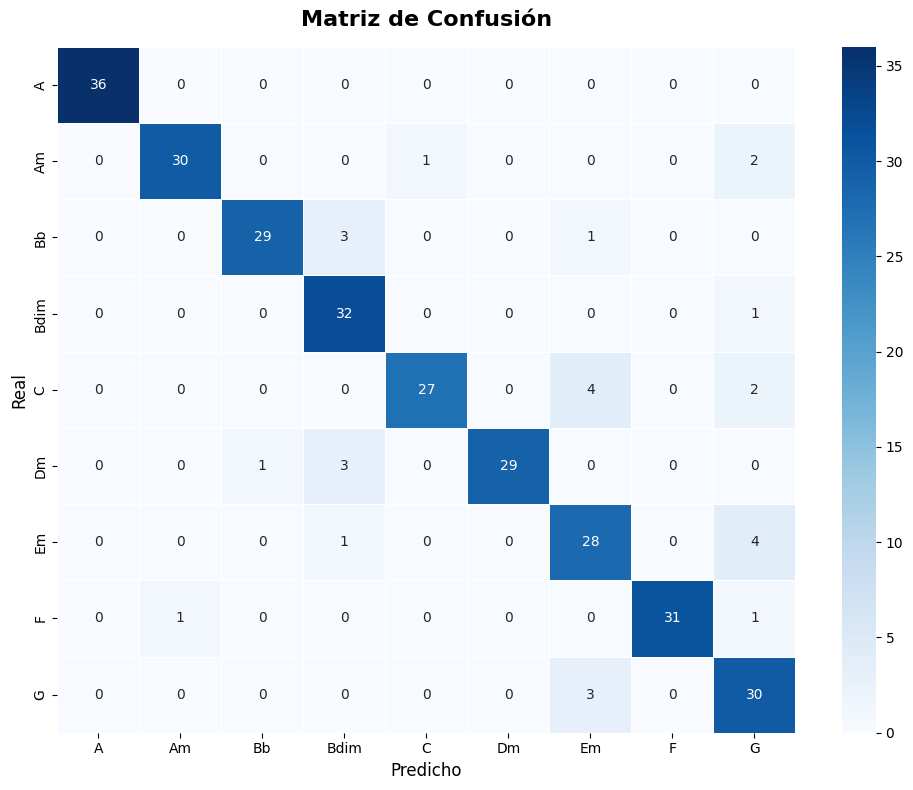

Guardada: matriz_confusion.png


In [16]:
# ── Matriz de confusión ─────────────────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)
plt.title('Matriz de Confusión', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Predicho', fontsize=12)
plt.ylabel('Real', fontsize=12)
plt.tight_layout()
plt.savefig('matriz_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardada: matriz_confusion.png')



### Métricas por acorde

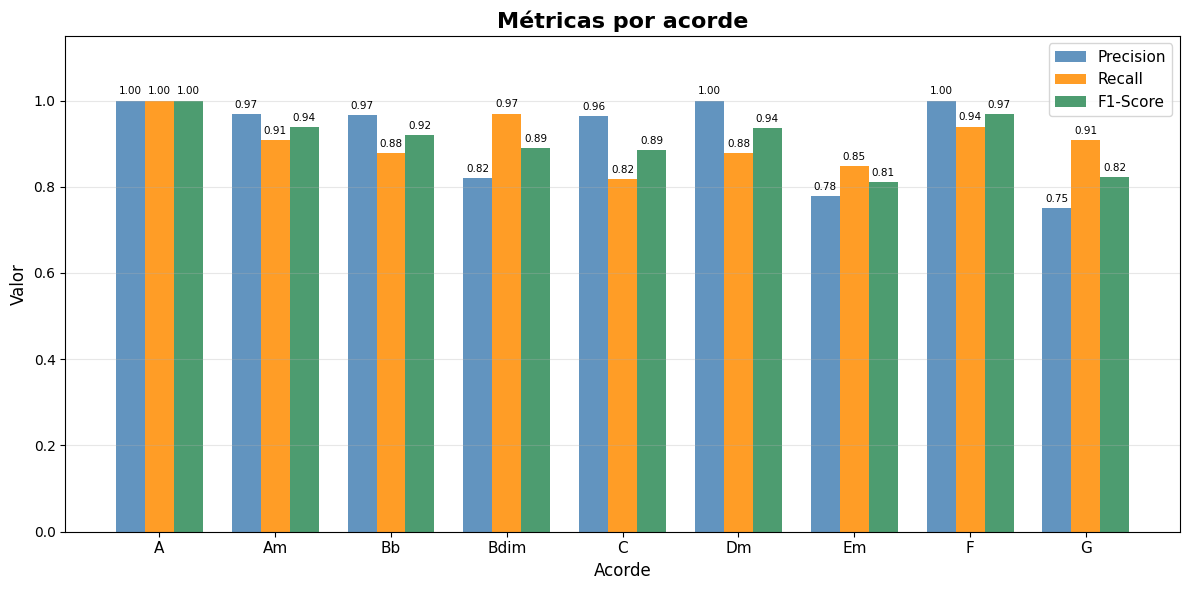

Guardada: metricas_por_acorde.png


In [17]:
# ── Métricas por acorde ─────────────────────────────────────────────
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(all_labels, all_preds, average=None, zero_division=0)
recall    = recall_score(all_labels,    all_preds, average=None, zero_division=0)
f1        = f1_score(all_labels,        all_preds, average=None, zero_division=0)

x     = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width, precision, width, label='Precision', color='steelblue',  alpha=0.85)
bars2 = ax.bar(x,         recall,    width, label='Recall',    color='darkorange', alpha=0.85)
bars3 = ax.bar(x + width, f1,        width, label='F1-Score',  color='seagreen',   alpha=0.85)

ax.set_title('Métricas por acorde', fontsize=16, fontweight='bold')
ax.set_xlabel('Acorde', fontsize=12)
ax.set_ylabel('Valor', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(class_names, fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.3)

for bar in [*bars1, *bars2, *bars3]:
    h = bar.get_height()
    ax.annotate(f'{h:.2f}',
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 3), textcoords='offset points',
        ha='center', va='bottom', fontsize=7.5)

plt.tight_layout()
plt.savefig('metricas_por_acorde.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardada: metricas_por_acorde.png')



Guardar modelo

In [18]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "classes": encoder.classes_
    },
    "transformer_guitar_chords.pth"
)

print("Modelo guardado")

Modelo guardado


In [19]:
# ── Cargar modelo guardado ──────────────────────────────────────────
import torch
import numpy as np
from sklearn.preprocessing import LabelEncoder

# Fix para PyTorch 2.6+ (permite cargar arrays de numpy)
torch.serialization.add_safe_globals([
    np.core.multiarray._reconstruct,
    np.ndarray,
    np.dtype,
    np.core.multiarray.scalar
])

checkpoint = torch.load(
    "transformer_guitar_chords.pth",
    map_location=DEVICE,
    weights_only=False  
)

model = AudioTransformer()
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

encoder = LabelEncoder()
encoder.classes_ = checkpoint["classes"]

print("Modelo cargado:", encoder.classes_)

Modelo cargado: ['A' 'Am' 'Bb' 'Bdim' 'C' 'Dm' 'Em' 'F' 'G']


C:\Users\Gerson\AppData\Local\Temp\ipykernel_17592\3641096483.py:8: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.multiarray.
  np.core.multiarray._reconstruct,
C:\Users\Gerson\AppData\Local\Temp\ipykernel_17592\3641096483.py:11: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumP

---
## 🎸 GuitarLearn — Aplicación Interactiva

**Modo 1:** Detección de acordes en tiempo real con diagrama visual  
**Modo 2:** Enseñanza — pega una canción cifrada y practica acorde por acorde con seguimiento por micrófono


In [20]:
# ── Importaciones adicionales para la aplicación ───────────────────────
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import numpy as np
import collections
import threading
import time
import re
import sounddevice as sd


### 🎵 Diagramas de acordes

In [21]:
CHORD_DATA = {
    'A': {
        'frets': ['x','0','2','2','2','0'], 'base': 1, 'barre': None,
        'desc': (
            "Dedo 1: cuerda D  - traste 2\n"
            "Dedo 2: cuerda G  - traste 2\n"
            "Dedo 3: cuerda B  - traste 2\n"
            "Cuerda A y e al aire\n"
            "Cuerda E silenciada"
        )
    },
    'Am': {
        'frets': ['x','0','2','2','1','0'], 'base': 1, 'barre': None,
        'desc': (
            "Dedo 1: cuerda B  - traste 1\n"
            "Dedo 2: cuerda D  - traste 2\n"
            "Dedo 3: cuerda G  - traste 2\n"
            "Cuerda A y e al aire"
        )
    },
    'Bb': {
        'frets': ['x','1','3','3','3','1'], 'base': 1, 'barre': 1,
        'desc': (
            "Cejilla (dedo 1) en traste 1, cuerdas A-e\n"
            "Dedo 2: cuerda D  - traste 3\n"
            "Dedo 3: cuerda G  - traste 3\n"
            "Dedo 4: cuerda B  - traste 3"
        )
    },
    'Bdim': {
        'frets': ['x','2','3','4','3','x'], 'base': 2, 'barre': None,
        'desc': (
            "Dedo 1: cuerda A  - traste 2\n"
            "Dedo 2: cuerda D  - traste 3\n"
            "Dedo 3: cuerda B  - traste 3\n"
            "Dedo 4: cuerda G  - traste 4\n"
            "Cuerdas E y e silenciadas"
        )
    },
    'C': {
        'frets': ['x','3','2','0','1','0'], 'base': 1, 'barre': None,
        'desc': (
            "Dedo 1: cuerda B  - traste 1\n"
            "Dedo 2: cuerda D  - traste 2\n"
            "Dedo 3: cuerda A  - traste 3\n"
            "Cuerdas G y e al aire"
        )
    },
    'Dm': {
        'frets': ['x','x','0','2','3','1'], 'base': 1, 'barre': None,
        'desc': (
            "Dedo 1: cuerda e  - traste 1\n"
            "Dedo 2: cuerda G  - traste 2\n"
            "Dedo 3: cuerda B  - traste 3\n"
            "Cuerda D al aire"
        )
    },
    'Em': {
        'frets': ['0','2','2','0','0','0'], 'base': 1, 'barre': None,
        'desc': (
            "Dedo 2: cuerda A  - traste 2\n"
            "Dedo 3: cuerda D  - traste 2\n"
            "Cuerdas E, G, B y e al aire"
        )
    },
    'F': {
        'frets': ['1','3','3','2','1','1'], 'base': 1, 'barre': 1,
        'desc': (
            "Cejilla (dedo 1) en traste 1, todas las cuerdas\n"
            "Dedo 2: cuerda G  - traste 2\n"
            "Dedo 3: cuerda A  - traste 3\n"
            "Dedo 4: cuerda D  - traste 3"
        )
    },
    'G': {
        'frets': ['3','2','0','0','0','3'], 'base': 1, 'barre': None,
        'desc': (
            "Dedo 2: cuerda A  - traste 2\n"
            "Dedo 3: cuerda E  - traste 3\n"
            "Dedo 4: cuerda e  - traste 3\n"
            "Cuerdas D, G, B al aire"
        )
    },
}

KNOWN_CHORDS = set(CHORD_DATA.keys())


In [22]:
def draw_chord_diagram(chord_name, ax=None, show_title=True, highlight=False):
    # Dibuja un diagrama de acorde de guitarra sobre un Axes de matplotlib.
    if chord_name not in CHORD_DATA:
        if ax is not None:
            ax.text(0.5, 0.5, '?\n' + chord_name, ha='center', va='center', fontsize=12)
            ax.axis('off')
        return

    data      = CHORD_DATA[chord_name]
    frets     = data['frets']
    base_fret = data.get('base', 1)
    barre     = data.get('barre')

    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=(2.8, 3.6))

    N_STRINGS = 6
    N_FRETS   = 4

    bg_color   = '#1a1a2e' if highlight else '#ffffff'
    line_color = '#cccccc' if highlight else '#333333'
    dot_color  = '#e94560' if highlight else '#1a1a2e'
    txt_color  = '#e94560' if highlight else '#333333'
    open_color = '#ffffff' if highlight else '#333333'

    ax.set_facecolor(bg_color)

    margin = 0.15
    sx = np.linspace(margin, 1 - margin, N_STRINGS)
    fy = np.linspace(0.83, 0.05, N_FRETS + 1)

    # Cejuela o indicador de traste
    nut_lw = 5 if base_fret == 1 else 1.5
    ax.plot([sx[0], sx[-1]], [fy[0], fy[0]], color=line_color, lw=nut_lw, solid_capstyle='butt')

    for y in fy[1:]:
        ax.plot([sx[0], sx[-1]], [y, y], color=line_color, lw=1, alpha=0.5)
    for x in sx:
        ax.plot([x, x], [fy[0], fy[-1]], color=line_color, lw=0.8, alpha=0.6)

    # Cejilla (barre)
    if barre is not None:
        fi = barre - base_fret
        if 0 <= fi < N_FRETS:
            y_b = (fy[fi] + fy[fi + 1]) / 2
            barre_idx = [i for i, f in enumerate(frets)
                         if f not in ('x', '0') and int(f) == barre]
            if len(barre_idx) >= 2:
                ax.plot([sx[min(barre_idx)], sx[max(barre_idx)]],
                        [y_b, y_b],
                        color=dot_color, lw=13, solid_capstyle='round', alpha=0.85, zorder=3)

    # Puntos de dedos y marcas
    for i, fv in enumerate(frets):
        x = sx[i]
        if fv == 'x':
            ax.text(x, fy[0] + 0.07, 'x', ha='center', va='bottom',
                    fontsize=11, color='#e94560', fontweight='bold', zorder=5)
        elif fv == '0':
            ax.text(x, fy[0] + 0.06, 'o', ha='center', va='bottom',
                    fontsize=11, color=open_color, zorder=5)
        else:
            fn = int(fv)
            fi = fn - base_fret
            if 0 <= fi < N_FRETS:
                y_d = (fy[fi] + fy[fi + 1]) / 2
                skip = False
                if barre is not None and fn == barre:
                    barre_idx2 = [j for j, f in enumerate(frets)
                                  if f not in ('x', '0') and int(f) == barre]
                    if barre_idx2 and min(barre_idx2) < i < max(barre_idx2):
                        skip = True
                if not skip:
                    ax.add_patch(plt.Circle((x, y_d), 0.045, color=dot_color, zorder=4))

    if base_fret > 1:
        ax.text(sx[-1] + 0.07, (fy[0] + fy[1]) / 2,
                str(base_fret) + 'fr', ha='left', va='center',
                fontsize=8, color=txt_color)

    # Etiquetas de cuerdas
    for i, label in enumerate(['E','A','D','G','B','e']):
        ax.text(sx[i], fy[-1] - 0.06, label,
                ha='center', va='top', fontsize=7, color=line_color, alpha=0.7)

    if show_title:
        ax.set_title(chord_name, fontsize=15, fontweight='bold',
                     color=txt_color, pad=6)

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.04, 1.07)
    ax.axis('off')

    if created_fig:
        plt.tight_layout()
        plt.show()


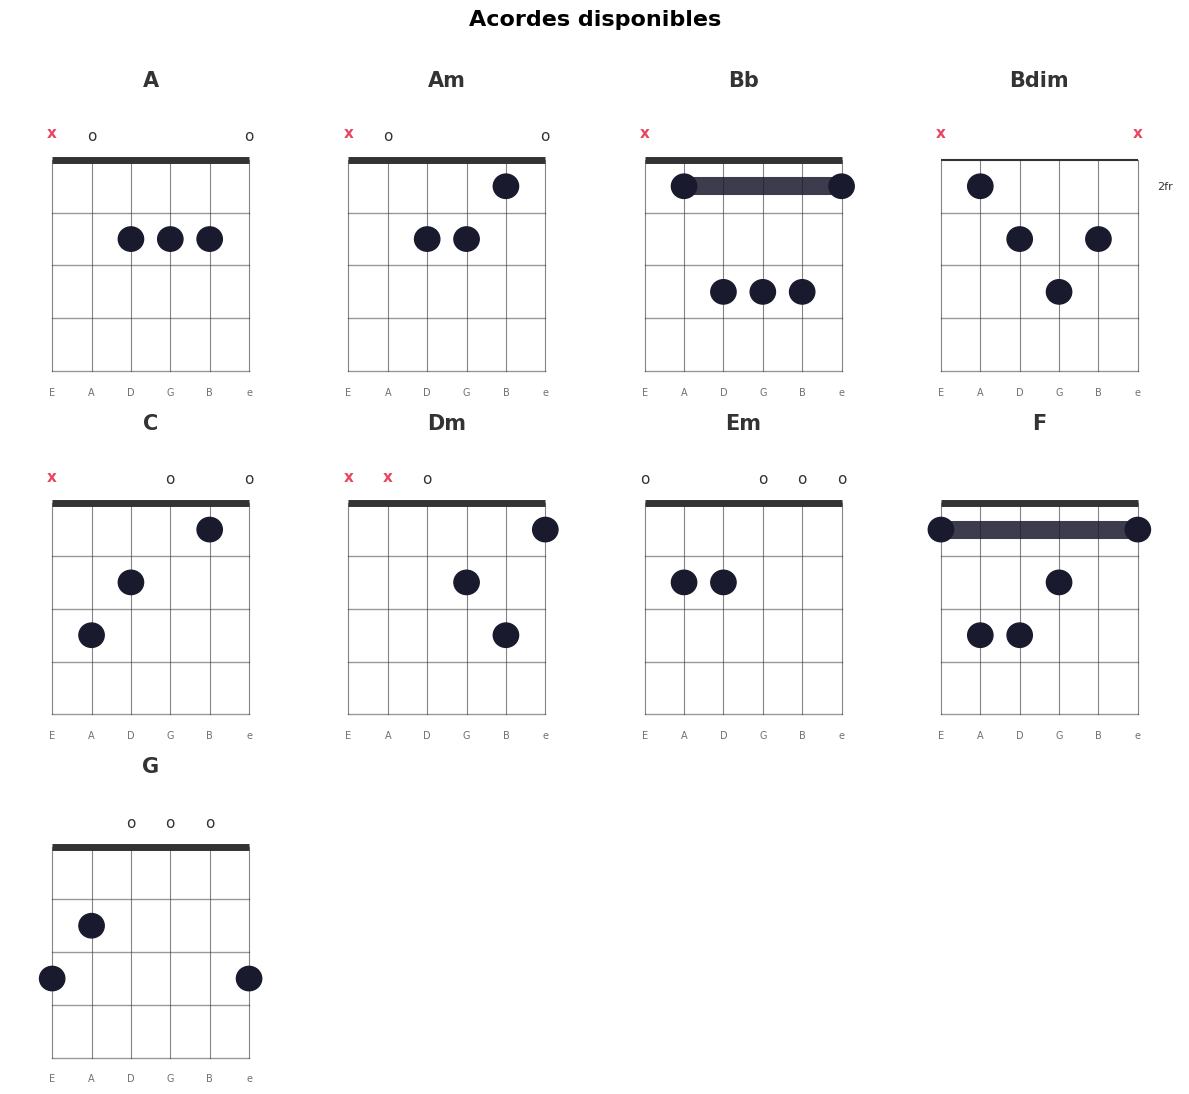

Guardado: acordes_todos.png


In [23]:
def show_all_chords():
    chords = list(CHORD_DATA.keys())
    cols   = 4
    rows   = (len(chords) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 3.6))
    axes_flat = axes.flatten()
    for i, chord in enumerate(chords):
        draw_chord_diagram(chord, ax=axes_flat[i])
    for j in range(len(chords), len(axes_flat)):
        axes_flat[j].axis('off')
    plt.suptitle('Acordes disponibles', fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig('acordes_todos.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('Guardado: acordes_todos.png')

show_all_chords()


### 🎼 Parser de canciones cifradas

In [24]:
# ── Parser de canciones en formato cifrado ──────────────────────────────
# Soporta el formato estandar: acordes sobre la letra
#
# Ejemplo:
#   [Verso]
#   Am        G       C
#   Letra de la cancion aqui

CHORD_RE = re.compile(r'\b(Am|Bb|Bdim|Dm|Em|[BCDEFG])\b')

def is_chord_line(line):
    # Retorna (True/False, lista_de_acordes) segun si la linea es de acordes.
    s = line.strip()
    if not s:
        return False, []
    found = CHORD_RE.findall(s)
    valid = [c for c in found if c in KNOWN_CHORDS]
    if not valid:
        return False, []
    remaining      = CHORD_RE.sub('', s).strip()
    total_chars    = max(len(s.replace(' ', '')), 1)
    remaining_chars = len(remaining.replace(' ', ''))
    chord_ratio    = 1 - remaining_chars / total_chars
    return chord_ratio > 0.50, valid


def parse_song(text):
    # Parsea el texto de una cancion cifrada.
    # Returns: chords_sequence, structured, unique_chords
    lines      = text.strip().split('\n')
    structured = []
    chords_seq = []

    for line in lines:
        is_chord, chords = is_chord_line(line)
        if is_chord:
            structured.append({'type': 'chords', 'content': line.rstrip(), 'chords': chords})
            chords_seq.extend(chords)
        elif line.strip().startswith('[') or line.strip().startswith('('):
            structured.append({'type': 'section', 'content': line.strip()})
        elif line.strip():
            structured.append({'type': 'lyric',   'content': line.rstrip()})
        else:
            structured.append({'type': 'empty',   'content': ''})

    seen, unique = set(), []
    for c in chords_seq:
        if c not in seen:
            seen.add(c)
            unique.append(c)

    return chords_seq, structured, unique


# Test rapido
_test = """
[Verso]
Am        G       C
Letra de prueba aqui
Am        G       Em
Otra linea
"""
_seq, _struct, _unique = parse_song(_test)
print("Secuencia:", _seq)
print("Unicos:   ", _unique)


Secuencia: ['Am', 'G', 'C', 'Am', 'G', 'Em']
Unicos:    ['Am', 'G', 'C', 'Em']


### 🔊 Parametros de escucha y funcion de prediccion

In [25]:
# ── Parametros globales de escucha ───────────────────────────────────────
WINDOW_SIZE    = 1.5
HOP_SIZE       = 0.25
RMS_THRESHOLD  = 0.01
VOTE_BUFFER_N  = 5

WINDOW_SAMPLES = int(WINDOW_SIZE * SAMPLE_RATE)
HOP_SAMPLES    = int(HOP_SIZE    * SAMPLE_RATE)

# ── Umbrales de confianza por acorde ─────────────────────────────────────
# Acordes con menor precision historica usan umbral mas bajo
# para no perder detecciones validas por distribucion "plana"
CHORD_THRESHOLDS = {
    'Am':   60,
    'Bb':   45,   # barre chord, distribucion plana -> umbral bajo
    'Bdim': 45,   # acorde diminuido, menos comun -> umbral bajo
    'C':    65,
    'Dm':   60,
    'Em':   55,
    'F':    55,
    'G':    45,   # comparte armonicos con Em/C -> umbral bajo
}
DEFAULT_THRESHOLD = 55

def predict_chunk(audio_chunk):
    # Recibe numpy array de audio y devuelve (acorde:str, confianza:float)
    if len(audio_chunk) < SAMPLES_PER_TRACK:
        audio_chunk = np.pad(audio_chunk, (0, SAMPLES_PER_TRACK - len(audio_chunk)))
    else:
        audio_chunk = audio_chunk[:SAMPLES_PER_TRACK]

    mfcc = librosa.feature.mfcc(
        y=audio_chunk.astype(np.float32),
        sr=SAMPLE_RATE, n_mfcc=N_MFCC
    ).T

    x = torch.tensor(mfcc).float().unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        preds, probs = model.predict_audio(x)

    chord      = encoder.inverse_transform([preds.cpu().item()])[0]
    confidence = probs.max().item() * 100
    return chord, confidence


def get_threshold(chord):
    # Retorna el umbral de confianza especifico para ese acorde
    return CHORD_THRESHOLDS.get(chord, DEFAULT_THRESHOLD)


def predict_with_threshold(audio_chunk):
    # Igual que predict_chunk pero aplica umbral por acorde.
    # Retorna (acorde, confianza, supera_umbral)
    chord, conf = predict_chunk(audio_chunk)
    threshold   = get_threshold(chord)
    return chord, conf, conf >= threshold


---
## 🎵 Modo 1 - Deteccion de acordes en tiempo real

In [26]:
def mode_detection():
    # Modo 1: deteccion en tiempo real con umbrales por acorde.
    # NOTA: todos los widgets se crean primero; el display se hace con un
    # unico VBox para garantizar renderizado consistente en Jupyter.

    header = widgets.HTML(
        '<div style="background:#1a1a2e; padding:16px; border-radius:10px;'
        ' border-left:4px solid #e94560; margin-bottom:10px;">'
        '<h2 style="color:#e94560; margin:0 0 4px 0;">Deteccion en Tiempo Real</h2>'
        '<p style="color:#a8a8b3; margin:0; font-size:13px;">'
        'Toca un acorde. El umbral de confianza se ajusta automaticamente por acorde.</p>'
        '</div>'
    )

    # ── Crear TODOS los widgets antes de cualquier display() ──────────────
    btn_start = widgets.Button(
        description='Iniciar', button_style='success',
        layout=widgets.Layout(width='150px', height='40px')
    )
    btn_stop = widgets.Button(
        description='Detener', button_style='danger',
        layout=widgets.Layout(width='150px', height='40px')
    )
    btn_stop.layout.display = 'none'   # ocultar despues de crear

    chord_html = widgets.HTML(
        '<div style="font-size:52px;font-weight:bold;color:#e94560;'
        'text-align:center;min-height:72px;">-</div>'
    )
    conf_bar = widgets.IntProgress(
        value=0, min=0, max=100, description='Confianza:',
        bar_style='info', style={'description_width':'80px'},
        layout=widgets.Layout(width='320px')
    )
    threshold_label = widgets.HTML(
        '<div style="font-size:11px;color:#888;text-align:center;">Umbral: -</div>'
    )
    out_diagram = widgets.Output()
    out_status  = widgets.Output(layout=widgets.Layout(min_height='40px'))
    out_history = widgets.Output(layout=widgets.Layout(
        max_height='220px', overflow_y='auto',
        border='1px solid #ddd', padding='8px'
    ))

    # ── Armar layout ANTES de display ─────────────────────────────────────
    btn_row = widgets.HBox([btn_start, btn_stop],
                           layout=widgets.Layout(margin='6px 0'))
    left_col = widgets.VBox(
        [chord_html, out_diagram, conf_bar, threshold_label],
        layout=widgets.Layout(min_width='220px', align_items='center')
    )
    right_col = widgets.VBox(
        [widgets.HTML('<b style="color:#555;font-size:13px;">Historial</b>'),
         out_history],
        layout=widgets.Layout(min_width='260px')
    )
    body = widgets.HBox([left_col, widgets.HTML('&nbsp;&nbsp;&nbsp;'), right_col])
    main_box = widgets.VBox([header, btn_row, out_status, body])

    # ── Un unico display() con el contenedor raiz ─────────────────────────
    display(main_box)

    # ── Logica de deteccion ────────────────────────────────────────────────
    stop_flag      = threading.Event()
    last_chord_ref = [None]
    timeline       = []

    def update_ui(voted, confidence, threshold):
        chord_html.value = (
            '<div style="font-size:52px;font-weight:bold;color:#e94560;'
            'text-align:center;">' + voted + '</div>'
        )
        conf_bar.value     = int(confidence)
        conf_bar.bar_style = ('success' if confidence > 75 else
                              'warning' if confidence > 50 else 'danger')
        threshold_label.value = (
            '<div style="font-size:11px;color:#888;text-align:center;">'
            'Umbral para ' + voted + ': ' + str(threshold) + '%</div>'
        )
        with out_diagram:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(3, 3.8))
            draw_chord_diagram(voted, ax=ax, highlight=True)
            plt.tight_layout()
            plt.show()

    def on_start(b):
        stop_flag.clear()
        last_chord_ref[0] = None
        timeline.clear()
        btn_start.layout.display = 'none'
        btn_stop.layout.display  = ''
        with out_status:
            clear_output(wait=True)
            print('Escuchando...')
        audio_buffer = np.zeros(WINDOW_SAMPLES, dtype=np.float32)
        vote_buffer  = collections.deque(maxlen=VOTE_BUFFER_N)
        start_time   = time.time()

        def audio_callback(indata, frames, time_info, status):
            new_audio = indata[:, 0]
            audio_buffer[:] = np.roll(audio_buffer, -len(new_audio))
            audio_buffer[-len(new_audio):] = new_audio
            rms = np.sqrt(np.mean(audio_buffer ** 2))
            if rms < RMS_THRESHOLD:
                with out_status:
                    clear_output(wait=True)
                    print('...silencio...')
                return
            chord, conf, passes = predict_with_threshold(audio_buffer.copy())
            vote_buffer.append((chord, passes))
            if len(vote_buffer) < VOTE_BUFFER_N:
                return
            valid_votes = [c for c, ok in vote_buffer if ok]
            if not valid_votes:
                return
            voted     = collections.Counter(valid_votes).most_common(1)[0][0]
            threshold = get_threshold(voted)
            if voted != last_chord_ref[0]:
                elapsed = round(time.time() - start_time, 2)
                timeline.append((voted, elapsed))
                last_chord_ref[0] = voted
                update_ui(voted, conf, threshold)
                with out_status:
                    clear_output(wait=True)
                    print(voted + '  ' + str(round(conf,1)) + '%  [' + str(elapsed) + 's]')
                with out_history:
                    print(str(elapsed) + 's -> ' + voted + ' (' + str(round(conf,0)) + '%)')

        def run():
            with sd.InputStream(samplerate=SAMPLE_RATE, channels=1,
                                 blocksize=HOP_SAMPLES, callback=audio_callback):
                while not stop_flag.is_set():
                    time.sleep(0.05)
            with out_status:
                clear_output(wait=True)
                print('Detenido.')

        threading.Thread(target=run, daemon=True).start()

    def on_stop(b):
        stop_flag.set()
        btn_start.layout.display = ''
        btn_stop.layout.display  = 'none'

    btn_start.on_click(on_start)
    btn_stop.on_click(on_stop)


---
## 📚 Modo 2 - Ensenanza de canciones

In [27]:
# ── Modo 2: Enseñanza con MP3 + acordes ──────────────────────────────────
# 1. Alumno sube MP3  →  Demucs separa la guitarra  →  reproduce guitarra limpia
# 2. Alumno pega el chart de acordes  →  se extrae la lista de acordes
# 3. Se muestra el acorde a tocar (nombre + diagrama)
# 4. El Transformer escucha el microfono y detecta si se toca el acorde correcto
# 5. Sin barra de tiempo: el alumno avanza cuando toca bien o con "Siguiente"

def mode_teaching():
    import re          as _re
    import tempfile    as _tmp
    import os          as _os
    import subprocess  as _sub
    import sys         as _sys
    import soundfile   as _sf

    # ══════════════════════════════════════════════════════════════════════
    # Helpers: parseo de chord chart
    # ══════════════════════════════════════════════════════════════════════
    _CHORD_RE = _re.compile(
        r'^[A-G][#b]?(?:m(?:aj)?|dim|aug|sus[24]?|M)?(?:\d+)?(?:/[A-G][#b]?)?$'
    )

    def normalize_chord(raw):
        root_part = raw.split('/')[0]
        m = _re.match(r'^([A-G][#b]?)(m(?:aj)?|dim|aug|sus[24]?)?', root_part)
        if not m:
            return root_part
        note    = m.group(1)
        quality = m.group(2) or ''
        if quality in ('m', 'min'):
            return note + 'm'
        elif quality == 'dim':
            return note + 'dim'
        else:
            return note

    def parse_chord_chart(text):
        raw_chords = []
        for line in text.split('\n'):
            stripped = line.lstrip()
            if not stripped or stripped[0] in ('>', '#'):
                continue
            # Lineas [Seccion] -> quitar el label y procesar el resto
            if stripped[0] == '[':
                line_clean = _re.sub(r'^\[[^\]]*\]\s*', '', stripped)
            else:
                line_clean = stripped
            # Quitar anotaciones entre parentesis: (Frase 1), (Coda), etc.
            line_clean = _re.sub(r'\([^)]*\)', '', line_clean)
            tokens = [t.rstrip(',.!?:;\'\"') for t in line_clean.split()]
            tokens = [t for t in tokens if t]
            if not tokens:
                continue
            if all(_CHORD_RE.match(t) for t in tokens):
                raw_chords.extend(tokens)
            elif (len(tokens) > 1
                  and not _CHORD_RE.match(tokens[0])
                  and all(_CHORD_RE.match(t) for t in tokens[1:])):
                raw_chords.extend(tokens[1:])
        normalized = [normalize_chord(c) for c in raw_chords]
        result = []
        for c in normalized:
            if not result or c != result[-1]:
                result.append(c)
        return result

    # ══════════════════════════════════════════════════════════════════════
    # Estado global
    # ══════════════════════════════════════════════════════════════════════
    state = {
        'chords':         [],    # lista de acordes del chart
        'idx':            0,
        'score':          0,
        'running':        False,
        'stop_flag':      threading.Event(),
        'vote_buffer':    collections.deque(maxlen=VOTE_BUFFER_N),
        'correct_streak': 0,
        'diagram_cache':  {},
    }
    STREAK_NEEDED = 1   # 1 deteccion correcta basta para avanzar

    # ══════════════════════════════════════════════════════════════════════
    # Widgets
    # ══════════════════════════════════════════════════════════════════════
    header = widgets.HTML(
        '<div style="background:#1a1a2e;padding:16px;border-radius:10px;'
        'border-left:4px solid #4CAF50;margin-bottom:12px;">'
        '<h2 style="color:#4CAF50;margin:0 0 4px 0;">Modo Enseñanza</h2>'
        '<p style="color:#a8a8b3;margin:0;font-size:13px;">'
        'Sube el MP3, pega los acordes y practica. '
        'El modelo detecta si tocas el acorde correcto.</p>'
        '</div>'
    )

    file_upload = widgets.FileUpload(
        accept='.mp3,.wav,.ogg,.m4a,.flac', multiple=False,
        description='Subir MP3',
        layout=widgets.Layout(width='160px')
    )
    chart_area = widgets.Textarea(
        placeholder='Pega aqui los acordes de la cancion\n'
                    'Ej:  Am  F  C  G\n'
                    'o en varias lineas:  Am | F | C | G',
        description='',
        layout=widgets.Layout(width='100%', height='150px')
    )
    btn_analyze = widgets.Button(
        description='Analizar', button_style='primary',
        layout=widgets.Layout(width='130px', display='none')
    )
    analyze_status = widgets.HTML('')
    audio_out = widgets.VBox(
        [], layout=widgets.Layout(display='none', margin='8px 0')
    )
    preview_out = widgets.Output(
        layout=widgets.Layout(
            max_height='80px', overflow_y='auto',
            border='1px solid #333', padding='8px',
            border_radius='6px', display='none'
        )
    )

    upload_section = widgets.VBox([
        widgets.HBox([file_upload, widgets.HTML('&nbsp;&nbsp;'), btn_analyze]),
        chart_area,
        analyze_status,
        audio_out,
        preview_out,
    ], layout=widgets.Layout(margin='0 0 10px 0'))

    # ── Zona de practica ───────────────────────────────────────────────────
    chord_big = widgets.HTML(
        '<div style="font-size:72px;font-weight:bold;color:#4CAF50;'
        'text-align:center;min-height:90px;letter-spacing:2px;">-</div>'
    )
    next_lbl = widgets.HTML(
        '<div style="font-size:16px;color:#a8a8b3;text-align:center;'
        'min-height:24px;"></div>'
    )
    diagram_img = widgets.Image(format='png', layout=widgets.Layout(width='220px', height='290px'))

    feedback_lbl = widgets.HTML(
        '<div style="font-size:36px;text-align:center;min-height:50px;"></div>'
    )
    score_lbl = widgets.HTML(
        '<div style="font-size:14px;color:#a8a8b3;text-align:center;"></div>'
    )
    out_status = widgets.Output(layout=widgets.Layout(min_height='24px'))

    btn_start = widgets.Button(
        description='Iniciar',  button_style='success',
        layout=widgets.Layout(width='130px', display='none')
    )
    btn_stop2 = widgets.Button(
        description='Detener',  button_style='danger',
        layout=widgets.Layout(width='130px', display='none')
    )
    btn_skip2 = widgets.Button(
        description='Siguiente ▶', button_style='',
        layout=widgets.Layout(width='130px', display='none')
    )

    diag_col = widgets.VBox(
        [diagram_img],
        layout=widgets.Layout(min_width='210px', align_items='center')
    )
    info_col = widgets.VBox(
        [chord_big, next_lbl, feedback_lbl, score_lbl],
        layout=widgets.Layout(min_width='280px', justify_content='center')
    )
    ctrl_row = widgets.HBox(
        [btn_start, btn_stop2, btn_skip2],
        layout=widgets.Layout(margin='8px 0')
    )
    content_box = widgets.VBox([
        widgets.HBox([diag_col, widgets.HTML('&nbsp;&nbsp;&nbsp;'), info_col]),
        ctrl_row,
        out_status,
    ], layout=widgets.Layout(display='none'))

    main_box = widgets.VBox([header, upload_section, content_box])
    display(main_box)

    # ══════════════════════════════════════════════════════════════════════
    # Helpers UI
    # ══════════════════════════════════════════════════════════════════════
    def _show_chord(chord, nxt=''):
        chord_big.value = (
            '<div style="font-size:72px;font-weight:bold;color:#4CAF50;'
            'text-align:center;letter-spacing:2px;">' + chord + '</div>'
        )
        next_lbl.value = (
            '<div style="font-size:16px;color:#a8a8b3;text-align:center;">'
            + ('▶ Siguiente: <b>' + nxt + '</b>' if nxt else '') + '</div>'
        )
        # Thread-safe: usar bytes pre-renderizados, no matplotlib desde el hilo
        diagram_img.value = state['diagram_cache'].get(chord, b'')

    def _set_feedback(correct, voted='', expected=''):
        if correct:
            feedback_lbl.value = (
                '<div style="font-size:36px;text-align:center;'
                'background:#1b3a1b;border-radius:8px;padding:4px 0;">'
                '✅ <span style="color:#4CAF50;font-weight:bold;">'
                + expected + '</span></div>'
            )
        else:
            show = voted if voted else '?'
            feedback_lbl.value = (
                '<div style="font-size:36px;text-align:center;'
                'background:#3a1b1b;border-radius:8px;padding:4px 0;">'
                '❌ <span style="color:#e94560;font-weight:bold;">'
                + show + '</span>'
                '<span style="color:#a8a8b3;font-size:20px;"> (esperado: '
                + expected + ')</span></div>'
            )

    def _clear_feedback():
        feedback_lbl.value = (
            '<div style="font-size:36px;text-align:center;min-height:50px;"></div>'
        )

    def _update_score():
        done  = state['idx']
        total = len(state['chords'])
        score_lbl.value = (
            '<div style="font-size:14px;color:#a8a8b3;text-align:center;">'
            'Correctos: <b style="color:#4CAF50;">' + str(state['score']) + '</b>'
            ' / ' + str(done) + '  —  Quedan: ' + str(total - done) + '</div>'
        )

    def _advance():
        """Avanza al siguiente acorde."""
        chords = state['chords']
        idx    = state['idx']
        nxt_idx = idx + 1
        if nxt_idx >= len(chords):
            # Cancion completada
            _stop_stream()
            chord_big.value = (
                '<div style="font-size:44px;font-weight:bold;'
                'color:#FFD700;text-align:center;">🎸 ¡Cancion completada!</div>'
            )
            next_lbl.value = ''
            score_lbl.value = (
                '<div style="font-size:18px;text-align:center;">'
                'Resultado: <b style="color:#4CAF50;">'
                + str(state['score']) + '</b> / ' + str(len(chords)) +
                ' correctos  (' +
                str(round(state['score'] / max(len(chords), 1) * 100)) + '%)</div>'
            )
            diagram_img.value = b''
            btn_stop2.layout.display = 'none'
            btn_skip2.layout.display = 'none'
            btn_start.layout.display = ''
            btn_start.description    = 'Reiniciar'
            return
        state['idx']            = nxt_idx
        state['correct_streak'] = 0
        state['vote_buffer'].clear()
        chord = chords[nxt_idx]
        nxt   = chords[nxt_idx + 1] if nxt_idx + 1 < len(chords) else ''
        _show_chord(chord, nxt)
        _clear_feedback()
        _update_score()
        with out_status:
            clear_output(wait=True)
            print(chord + '  [' + str(nxt_idx + 1) + '/' + str(len(chords)) + ']')

    def _stop_stream():
        state['stop_flag'].set()
        state['running'] = False

    # ══════════════════════════════════════════════════════════════════════
    # Microfono + deteccion en tiempo real
    # ══════════════════════════════════════════════════════════════════════
    def _start_mic():
        state['stop_flag'].clear()
        state['running'] = True
        state['vote_buffer'].clear()
        state['correct_streak'] = 0
        audio_buf = [np.zeros(WINDOW_SAMPLES, dtype=np.float32)]

        def _audio_cb(indata, frames, ti, status):
            if not state['running']:
                return
            new_a = indata[:, 0]
            audio_buf[0] = np.roll(audio_buf[0], -len(new_a))
            audio_buf[0][-len(new_a):] = new_a
            rms = np.sqrt(np.mean(audio_buf[0] ** 2))
            if rms < RMS_THRESHOLD:
                return

            chord, conf, passes = predict_with_threshold(audio_buf[0].copy())
            state['vote_buffer'].append((chord, passes))

            if len(state['vote_buffer']) < VOTE_BUFFER_N:
                return

            valid = [c for c, ok in state['vote_buffer'] if ok]
            if not valid:
                return

            voted    = collections.Counter(valid).most_common(1)[0][0]
            expected = state['chords'][state['idx']] if state['idx'] < len(state['chords']) else ''

            if voted == expected:
                state['correct_streak'] += 1
                _set_feedback(True, expected=expected)
                if state['correct_streak'] >= STREAK_NEEDED:
                    state['score'] += 1
                    _advance()
            else:
                state['correct_streak'] = 0
                _set_feedback(False, voted=voted, expected=expected)
                # NO avanza — el alumno debe tocar el acorde correcto para continuar

        def _mic_run():
            with sd.InputStream(samplerate=SAMPLE_RATE, channels=1,
                                 blocksize=HOP_SAMPLES, callback=_audio_cb):
                while not state['stop_flag'].is_set():
                    time.sleep(0.05)

        threading.Thread(target=_mic_run, daemon=True).start()

    # ══════════════════════════════════════════════════════════════════════
    # Carga, Demucs y analisis
    # ══════════════════════════════════════════════════════════════════════
    def on_upload(change):
        if file_upload.value:
            btn_analyze.layout.display = ''

    def on_analyze(b):
        analyze_status.value = '<span style="color:#2196F3;">⏳ Procesando...</span>'
        audio_out.layout.display   = 'none'
        preview_out.layout.display = 'none'
        content_box.layout.display = 'none'
        btn_start.layout.display   = 'none'

        chart_text = chart_area.value.strip()
        if not chart_text:
            analyze_status.value = '<span style="color:#e94560;">Pega los acordes primero.</span>'
            return

        chart_chords = parse_chord_chart(chart_text)
        if not chart_chords:
            analyze_status.value = '<span style="color:#e94560;">No se detectaron acordes. Revisa el formato.</span>'
            return

        uploaded = file_upload.value
        if not uploaded:
            analyze_status.value = '<span style="color:#e94560;">Sube el MP3 primero.</span>'
            return

        if isinstance(uploaded, (list, tuple)):
            data        = uploaded[0]
            fname       = data['name']
            audio_bytes = bytes(data['content'])
        else:
            fname       = list(uploaded.keys())[0]
            d           = uploaded[fname]
            audio_bytes = d['content'] if isinstance(d, dict) else bytes(d)
        ext = '.' + fname.rsplit('.', 1)[-1].lower() if '.' in fname else '.mp3'

        def _run_demucs():
            try:
                analyze_status.value = (
                    '<span style="color:#2196F3;">⏳ Separando guitarra con Demucs '
                    '(primera vez descarga ~150MB)...</span>'
                )
                tmp_dir = _tmp.mkdtemp()
                src     = _os.path.join(tmp_dir, 'song' + ext)
                out_dir = _os.path.join(tmp_dir, 'out')
                _os.makedirs(out_dir, exist_ok=True)
                with open(src, 'wb') as fp:
                    fp.write(audio_bytes)

                # ── Demucs: separar los 6 stems completos ─────────────────────
                proc = _sub.run(
                    [_sys.executable, '-m', 'demucs',
                     '-n', 'htdemucs_6s',
                     '--out', out_dir, src],
                    capture_output=True, text=True, timeout=600
                )

                # Recolectar stems por nombre
                stems = {}
                STEM_NAMES = ('vocals', 'drums', 'bass', 'guitar', 'piano', 'other')
                if proc.returncode == 0:
                    for root2, _, files2 in _os.walk(out_dir):
                        for fname2 in files2:
                            name = fname2.replace('.wav', '')
                            if name in STEM_NAMES:
                                stems[name] = _os.path.join(root2, fname2)

                if 'guitar' in stems:
                    import soundfile as _sf2
                    import numpy as _np2

                    def _mix_stems(stem_paths):
                        """Mezcla una lista de archivos WAV sumando sus senales."""
                        mixed, sr2 = None, None
                        for sp in stem_paths:
                            data, sr2 = _sf2.read(sp, always_2d=True)
                            mixed = data if mixed is None else mixed + data
                        return mixed, sr2

                    def _to_bytes(data, sr2):
                        """Convierte array numpy a bytes WAV en memoria."""
                        import io as _io
                        buf = _io.BytesIO()
                        _sf2.write(buf, data, sr2, format='WAV', subtype='FLOAT')
                        return buf.getvalue()

                    # Solo guitarra
                    guitar_data, sr2 = _sf2.read(stems['guitar'], always_2d=True)
                    guitar_bytes = _to_bytes(guitar_data, sr2)

                    # Sin guitarra: todos los stems menos guitarra
                    no_guitar_keys = [k for k in STEM_NAMES if k != 'guitar' and k in stems]
                    no_guitar_data, _ = _mix_stems([stems[k] for k in no_guitar_keys])
                    no_guitar_bytes = _to_bytes(no_guitar_data, sr2)

                    # Sin voz (karaoke): todos los stems menos vocals
                    karaoke_keys = [k for k in STEM_NAMES if k != 'vocals' and k in stems]
                    karaoke_data, _ = _mix_stems([stems[k] for k in karaoke_keys])
                    karaoke_bytes = _to_bytes(karaoke_data, sr2)

                    analyze_status.value = (
                        '<span style="color:#4CAF50;">✅ Separacion completada — '
                        + str(len(chart_chords)) + ' acordes cargados</span>'
                    )
                    audio_out.children = [
                        widgets.HTML('<b>🎸 Solo guitarra:</b>'),
                        widgets.Audio(value=guitar_bytes,    format='wav', autoplay=False),
                        widgets.HTML('<b>🎵 Cancion SIN guitarra:</b>'),
                        widgets.Audio(value=no_guitar_bytes, format='wav', autoplay=False),
                        widgets.HTML('<b>🎤 Cancion SIN voz (karaoke):</b>'),
                        widgets.Audio(value=karaoke_bytes,   format='wav', autoplay=False),
                    ]
                    audio_out.layout.display = ''
                else:
                    analyze_status.value = (
                        '<span style="color:#e94560;">⚠️ Demucs fallo — '
                        'practica igual con los acordes del chart.</span>'
                    )

                # Guardar acordes y mostrar preview
                state['chords'] = chart_chords
                preview_out.layout.display = ''
                with preview_out:
                    clear_output(wait=True)
                    print('Acordes: ' + '  →  '.join(chart_chords[:16])
                          + ('  ...' if len(chart_chords) > 16 else ''))

                btn_start.layout.display   = ''
                content_box.layout.display = ''

            except Exception as _e:
                analyze_status.value = '<span style="color:#e94560;">Error: ' + str(_e) + '</span>'

        threading.Thread(target=_run_demucs, daemon=True).start()

    # ══════════════════════════════════════════════════════════════════════
    # Handlers de control
    # ══════════════════════════════════════════════════════════════════════
    def on_start(b):
        _stop_stream()
        time.sleep(0.15)
        chords = state['chords']
        if not chords:
            return
        state['idx']            = 0
        state['score']          = 0
        state['correct_streak'] = 0
        btn_start.layout.display = 'none'
        btn_stop2.layout.display = ''
        btn_skip2.layout.display = ''
        _clear_feedback()
        nxt = chords[1] if len(chords) > 1 else ''
        _show_chord(chords[0], nxt)
        _update_score()
        with out_status:
            clear_output(wait=True)
            print(chords[0] + '  [1/' + str(len(chords)) + ']')
        # Pre-renderizar diagramas a PNG (thread-safe para el hilo del mic)
        import io as _io_diag
        cache = {}
        for _ch in set(state['chords']):
            if _ch in CHORD_DATA:
                _fig, _ax = plt.subplots(figsize=(2.8, 3.5))
                draw_chord_diagram(_ch, ax=_ax, highlight=True)
                plt.tight_layout()
                _buf = _io_diag.BytesIO()
                _fig.savefig(_buf, format='png', dpi=100, bbox_inches='tight')
                plt.close(_fig)
                _buf.seek(0)
                cache[_ch] = _buf.read()
        state['diagram_cache'] = cache
        _start_mic()

    def on_stop2(b):
        _stop_stream()
        btn_stop2.layout.display = 'none'
        btn_skip2.layout.display = 'none'
        btn_start.layout.display = ''
        btn_start.description    = 'Reanudar'

    def on_skip2(b):
        if state['idx'] < len(state['chords']):
            _advance()

    # ── Wiring ─────────────────────────────────────────────────────────────
    file_upload.observe(on_upload, names='value')
    btn_analyze.on_click(on_analyze)
    btn_start.on_click(on_start)
    btn_stop2.on_click(on_stop2)
    btn_skip2.on_click(on_skip2)
# mode_teaching() NO se llama aqui -- lo llama el launcher (celda Lanzar GuitarLearn)


---
## Lanzar GuitarLearn

In [29]:
# =====================================================================
# GUITARLEARN  -  Ejecuta esta celda para abrir la aplicacion
# =====================================================================

def launch_guitarlearn():
    banner = widgets.HTML(
        '<div style="background:linear-gradient(135deg,#1a1a2e,#16213e);'
        ' padding:24px; border-radius:12px; margin-bottom:14px;'
        ' border-left:5px solid #e94560;">'
        '<h1 style="color:white; margin:0; font-size:26px;">GuitarLearn</h1>'
        '<p style="color:#a8a8b3; margin:6px 0 0 0; font-size:14px;">'
        'Deteccion y ensenanza de acordes de guitarra con IA</p>'
        '<div style="margin-top:8px; font-size:12px; color:#e94560;">'
        'Transformer - 1760 audios - 8 acordes - 94% precision</div>'
        '</div>'
    )

    tab = widgets.Tab(layout=widgets.Layout(width='100%'))
    out1 = widgets.Output()
    out2 = widgets.Output()
    tab.children = [out1, out2]
    tab.set_title(0, 'Modo 1: Deteccion en tiempo real')
    tab.set_title(1, 'Modo 2: Ensenanza de canciones')

    with out1:
        mode_detection()
    with out2:
        mode_teaching()

    display(banner, tab)

launch_guitarlearn()


HTML(value='<div style="background:linear-gradient(135deg,#1a1a2e,#16213e); padding:24px; border-radius:12px; …